# xdflow quickstart

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/general-sense/xdflow/blob/main/examples/notebooks/quickstart.ipynb)

A complete xdflow workflow on a small synthetic dataset, in a few seconds and with only the base install. You'll build
labeled trials as an `xarray.DataArray` with `trial`, `channel` and `time` dimensions, wrap them in a `DataContainer`,
and run a three-step pipeline (z-score, flatten, logistic regression) whose classifier reads its target from the
`stimulus` coordinate. `KFoldValidator` owns the evaluation loop: it stratifies folds by that coordinate and refits the
stateful step on every training fold. The final predictions stay aligned with the trial metadata. The same code is in
the [5-Minute Core Quickstart](https://xdflow.readthedocs.io/en/latest/tutorials/quickstart/) tutorial.

In [ ]:
# Install xdflow from GitHub. After the 0.3 release this becomes: %pip install "xdflow>=0.3"
%pip install -q "xdflow @ git+https://github.com/general-sense/xdflow@main"

## 1. Create structured data

xdflow starts from named dimensions and sample-level coordinates. Each trial has `channel` and `time` dimensions, plus
`stimulus` and `session` metadata. The toy signal is planted on purpose: `tone` trials get a bump on `ch1`, `odor`
trials a later bump on `ch2`, and `rest` trials are noise only.

In [1]:
import numpy as np
import xarray as xr

from xdflow.core import DataContainer

rng = np.random.default_rng(0)

stimuli = np.repeat(["rest", "tone", "odor"], 60)
rng.shuffle(stimuli)

values = rng.normal(0.0, 0.8, size=(stimuli.size, 4, 25))
values[stimuli == "tone", 1, 8:15] += 2.0
values[stimuli == "odor", 2, 14:22] += 2.0

trial_ids = np.arange(stimuli.size)

data = xr.DataArray(
    values,
    dims=("trial", "channel", "time"),
    coords={
        "trial": trial_ids,
        "channel": [f"ch{i}" for i in range(4)],
        "time": np.linspace(-0.2, 0.8, 25),
        "stimulus": ("trial", stimuli),
        "session": ("trial", np.where(trial_ids < stimuli.size // 2, "session_a", "session_b")),
    },
)
container = DataContainer(data)
data

<xarray.DataArray (trial: 180, channel: 4, time: 25)> Size: 144kB
array([[[ 0.20676223, -0.45483956, -0.82384355, ...,  0.86413073,
         -0.2310132 ,  0.06678028],
        [-0.67968476, -0.40849797, -0.00922645, ...,  0.49055126,
         -0.12175437, -1.17911036],
        [ 0.82308348, -1.54796771, -0.19194934, ...,  0.46906983,
         -0.53082816, -0.49073428],
        [-1.28411952,  0.58347952,  0.64491149, ..., -0.40000675,
          1.08835696,  0.80191862]],

       [[-0.12187091, -0.37777275, -0.80384081, ..., -0.97697868,
          0.161528  , -0.03106803],
        [ 0.85305964, -0.73730714,  0.64377355, ..., -0.78046626,
         -0.01735269,  0.02778223],
        [-0.59548848, -1.02925957,  1.1379028 , ...,  0.66631556,
          0.96260716,  0.50965859],
        [ 0.44667197, -3.01782012,  0.2085038 , ...,  0.76590849,
         -0.09106908,  0.334682  ]],

       [[-0.30082172,  0.05405536, -0.23302633, ...,  0.49770018,
         -1.2232743 ,  1.62142328],
...
        [ 1.98456942, -0.18510391,  0.84515301, ..., -0.12949354,
          0.06105648,  0.0987743 ]],

       [[-0.32695626,  0.3172134 ,  0.85624771, ..., -0.88559036,
          0.10705874, -0.41056447],
        [-0.88431074, -0.09852901, -0.78402031, ..., -0.92507895,
         -0.65718868,  0.28453694],
        [-0.63545428, -1.08152069,  0.68727096, ..., -0.0706057 ,
          0.073687  ,  0.16729   ],
        [-2.15067668,  0.38100712, -0.73866409, ..., -0.18997933,
          0.24749516, -0.9420909 ]],

       [[ 0.53235143,  0.29483825,  0.96959775, ..., -0.70096235,
          0.44096035,  0.74588456],
        [-0.4794968 ,  1.07443734, -1.02414423, ..., -1.02101111,
          0.44820856, -0.04327383],
        [ 1.61872947, -1.10189922, -0.28076928, ...,  1.23155532,
          0.16302865, -0.228785  ],
        [ 1.4597565 ,  1.66055199,  0.49778357, ...,  0.51482234,
          0.39108517, -1.27721796]]], shape=(180, 4, 25))
Coordinates:
  * trial     (trial) int64 1kB 0 1 2 3 4 5 6 7 ... 173 174 175 176 177 178 179
    stimulus  (trial) <U4 3kB 'odor' 'rest' 'odor' ... 'odor' 'rest' 'tone'
    session   (trial) <U9 6kB 'session_a' 'session_a' ... 'session_b'
  * channel   (channel) <U3 48B 'ch0' 'ch1' 'ch2' 'ch3'
  * time      (time) float64 200B -0.2 -0.1583 -0.1167 ... 0.7167 0.7583 0.8

Because `stimulus` is a coordinate, the class averages are a `groupby` away, with no separate label array to keep in
sync with the data:

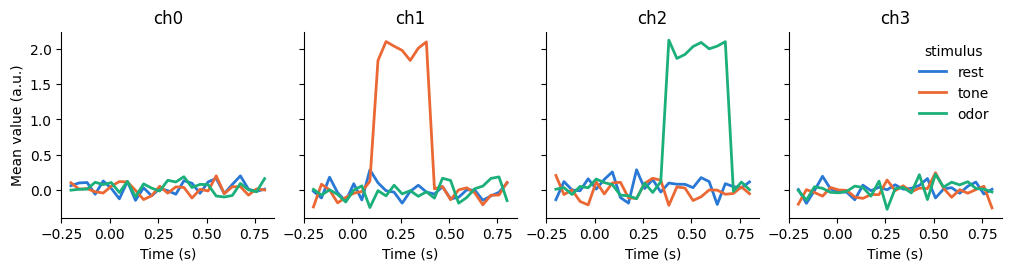

In [2]:
import matplotlib.pyplot as plt

class_means = data.groupby("stimulus").mean("trial")
colors = {"rest": "#2a78d6", "tone": "#eb6834", "odor": "#1baf7a"}

fig, axes = plt.subplots(1, 4, figsize=(10, 2.6), sharey=True, layout="constrained")
for ax, channel in zip(axes, data["channel"].values, strict=True):
    for stimulus, color in colors.items():
        trace = class_means.sel(stimulus=stimulus, channel=channel)
        ax.plot(trace["time"], trace, color=color, linewidth=2, label=stimulus)
    ax.set_title(channel)
    ax.set_xlabel("Time (s)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Mean value (a.u.)")
axes[-1].legend(title="stimulus", frameon=False)
plt.show()

## 2. Build a pipeline

The pipeline keeps labels and coordinates attached while each step transforms the data. The classifier reads its
targets from the `stimulus` coordinate.

In [3]:
from sklearn.linear_model import LogisticRegression

from xdflow.composite import Pipeline
from xdflow.transforms.basic_transforms import FlattenTransform
from xdflow.transforms.normalization import ZScoreTransform
from xdflow.transforms.sklearn_transform import SKLearnPredictor

pipeline = Pipeline(
    name="core_quickstart",
    steps=[
        ("zscore", ZScoreTransform(per_dim="trial")),
        ("flatten", FlattenTransform(dims=("channel", "time"))),
        (
            "classifier",
            SKLearnPredictor(
                LogisticRegression,
                sample_dim="trial",
                target_coord="stimulus",
                max_iter=500,
            ),
        ),
    ],
)

## 3. Cross-validate

`KFoldValidator` owns the split loop, scoring, prediction collection and stateful refits. `stratify_coord` keeps class
proportions balanced across folds using the named `stimulus` coordinate.

In this pipeline, z-scoring is per trial and flattening is structural, so that fold-invariant preprocessing can run
before the stateful classifier is cloned and refit on each training fold.

In [4]:
from xdflow.cv import KFoldValidator

cv = KFoldValidator(
    n_splits=5,
    shuffle=True,
    random_state=0,
    stratify_coord="stimulus",
    scoring="f1_weighted",
    verbose=False,
)
cv.set_pipeline(pipeline)

score = cv.cross_validate(container, verbose=False)
print(f"Weighted F1: {score:.3f}")

Weighted F1: 1.000


The planted signal is strong, so a near-perfect score is expected on this toy data. The point of the example is the
mechanics, not the number.

## 4. Fit and predict

After choosing a pipeline, fit it on the data you want to use for the final model and call `predict`.

In [5]:
pipeline.fit(container)
predictions = pipeline.predict(container)

print(predictions.data.dims)

('trial',)


The prediction container still carries the `trial` dimension and its coordinates, so predictions line up with
trial-level metadata without any index bookkeeping. (These are in-sample predictions from the final model; the
cross-validated score above is the performance estimate.)

In [6]:
predictions.data.to_dataframe(name="predicted")[["stimulus", "session", "predicted"]].head()

,stimulus,session,predicted
trial,,,
0,odor,session_a,odor
1,rest,session_a,rest
2,odor,session_a,odor
3,odor,session_a,odor
4,tone,session_a,tone


## Next steps

- Read [Data Contract](https://xdflow.readthedocs.io/en/latest/concepts/data_contract/) before adapting your own arrays.
- Use [Writing Custom Transforms](https://xdflow.readthedocs.io/en/latest/guides/writing-transforms/) when your preprocessing should become a reusable
  pipeline step.
- Use [Hyperparameter Tuning](https://xdflow.readthedocs.io/en/latest/tutorials/tuning/) to search over the same kind of pipeline with Optuna.
- Try the [EEG motor imagery notebook](https://colab.research.google.com/github/general-sense/xdflow/blob/main/examples/notebooks/eeg_motor_imagery.ipynb)
  for the same ideas on real data, side by side with plain scikit-learn.